# Week 2 RAG evaluation pipeline

This notebook validates the frozen bilingual dataset, explains the three core
metrics, replays the recorded experiment, and analyzes its results. It uses saved
responses, inspected claim proposals, and embedding vectors. Running every cell
does not download weights or generate new responses. A fresh inference run is a
separately recorded experiment described in the repository setup instructions.

Context recall measures evidence sufficiency. Faithfulness is reported explicitly
as an embedding retrieval proxy. Semantic relevance is raw multilingual cosine.
Lexical reference recall is a separate diagnostic. Primary results use the eighty
held-out cases; calibration and full-dataset summaries remain separately labeled.


In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'dataset_config.json').is_file())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'scripts/datasets'))
config = json.loads((ROOT / 'configs/week-02.json').read_text())
OUT = ROOT / config['output']
records = [json.loads(line) for line in (ROOT / config['dataset']).read_text().splitlines()]
scores = json.loads((OUT / 'scores.json').read_text())
manifest = json.loads((OUT / 'run_manifest.json').read_text())
calibration = json.loads((OUT / 'calibration.json').read_text())
print('Run:', manifest['run_name'])
print('Records:', len(records), '| primary held-out cases:', sum(r['evaluation_labels']['subset'] == 'held_out' for r in records))


Run: w02-qwen25-7b-mlx4bit-fixed-v1
Records: 100 | primary held-out cases: 80


## Dataset and manifest validation

The metadata repair preserved all reviewed dialogue. Validate both data and schema
hashes, source collection identity, construction inputs, and claimed review snapshots.


In [2]:
from validate_dataset import validate_records, manifest_errors
dataset_config = json.loads((ROOT / 'dataset_config.json').read_text())
for role, profile in [('collection', 'release'), ('pilot', 'pilot')]:
    path = ROOT / 'data' / dataset_config[role]['file']
    rows = [json.loads(line) for line in path.read_text().splitlines()]
    report = validate_records(rows, profile)
    integrity = manifest_errors(path, json.loads(path.with_suffix('.manifest.json').read_text()))
    assert report['valid'] and not report['warnings'] and not integrity
    print(profile, report['record_count'], 'records: zero errors, zero warnings; all manifest inputs match')
assert hashlib.sha256((ROOT / config['dataset']).read_bytes()).hexdigest() == manifest['dataset_sha256']


release 100 records: zero errors, zero warnings; all manifest inputs match
pilot 12 records: zero errors, zero warnings; all manifest inputs match


## Metric computations and language paths

Required facts remain stable when evidence is withheld. In case 0006 the start
time is supplied but the room is missing, yielding context recall 1/2. Geometry
examples independently verify cosine arithmetic. The complete pytest suite adds
three hand-calculated examples per metric and tests errors, language paths, and
grouped statistics.


In [3]:
from src.evaluator import context_recall, cosine, tokenize
case6 = next(r for r in records if r['id'] == 'w01-fari-zh-0006-base')
assert context_recall(case6).value == 0.5
assert cosine([1, 0], [0, 1]) == 0
assert cosine([1, 0], [-1, 0]) == -1
assert abs(cosine([3, 4], [4, 3]) - 24/25) < 1e-12
case5 = next(r for r in records if r['id'] == 'w01-fari-zh-0005-base')
print('Case 0006 context recall:', context_recall(case6).value)
print('Chinese mixed query tokens:', tokenize(case5['query'], 'zh'))
embedding_metadata = json.loads((OUT / 'embeddings.json').read_text())
print('Multilingual encoder:', embedding_metadata['model_id'])
print('Immutable revision:', embedding_metadata['revision'])


Case 0006 context recall: 0.5


Chinese mixed query tokens: ['今晚', '的', 'video', 'call', '几点', '提醒', '我来', '着']
Multilingual encoder: intfloat/multilingual-e5-base
Immutable revision: d128750597153bb5987e10b1c3493a34e5a4502a


## Exact score replay

Replay recomputes every case and aggregate from saved inputs and vectors with the
same metric functions. It requires exact agreement and retains explicit null/error
statuses. This checks score reproducibility independently of model generation.


In [4]:
from src.experiment import score_run
replayed = score_run(ROOT, config, replay=True)
assert replayed == scores


Exact score replay passed for all cases and aggregates.


## Overall and held-out results

Means and population standard deviations use defined values only. Denominators
and errors remain visible. Context recall is based on dataset evidence, not the
generated response. Faithfulness proxy scores require their calibration caveat.


In [5]:
def summary_frame(summary):
    return pd.DataFrame([{'metric': name, **stats} for name, stats in summary.items()])
display(summary_frame(scores['aggregate']['overall']).round(4))
display(summary_frame(scores['aggregate']['by_subset']['held_out']).round(4))

frame = pd.DataFrame([{'id': row['id'], 'domain': row['domain'],
                      'difficulty': row['difficulty'], 'subset': row['subset'],
                      **{key: value['value'] for key, value in row['metrics'].items()}}
                     for row in scores['per_example']])
held = frame[frame['subset'] == 'held_out']


,metric,n_total,n_scored,n_not_applicable,n_errors,n_empty_response,mean,std_population
0,context_recall,100,96,4,0,0,0.9167,0.2569
1,faithfulness_proxy,100,99,1,0,0,0.9645,0.1151
2,lexical_reference_recall,100,100,0,0,0,0.5166,0.2279
3,semantic_relevance,100,100,0,0,0,0.8841,0.0408


,metric,n_total,n_scored,n_not_applicable,n_errors,n_empty_response,mean,std_population
0,context_recall,80,77,3,0,0,0.9286,0.2379
1,faithfulness_proxy,80,80,0,0,0,0.9602,0.1224
2,lexical_reference_recall,80,80,0,0,0,0.5207,0.2204
3,semantic_relevance,80,80,0,0,0,0.8852,0.0380


## Domain and difficulty breakdowns

The full dataset satisfies the specified 40/20/25/15 domain allocation. The primary
held-out group has 32 Fari English, 16 Fari Chinese, 20 Senpai English, and 12 Senpai
Chinese cases. Native scenarios differ, so score gaps do not identify a causal
language effect.


In [6]:
for group in ['domain', 'difficulty']:
    tables = []
    for label, subset in held.groupby(group):
        table = subset[['context_recall', 'faithfulness_proxy', 'semantic_relevance']].agg(['count', 'mean', lambda x: x.std(ddof=0)])
        table.index = ['n_scored', 'mean', 'std_population']
        tables.append((label, table.round(4)))
    for label, table in tables:
        print(group, label)
        display(table)


domain fari-en


,context_recall,faithfulness_proxy,semantic_relevance
n_scored,31.0000,32.0000,32.0000
mean,0.8871,0.9702,0.8628
std_population,0.3035,0.0829,0.0283


domain fari-zh


,context_recall,faithfulness_proxy,semantic_relevance
n_scored,15.0000,16.0,16.0000
mean,0.9667,1.0,0.9188
std_population,0.1247,0.0,0.0238


domain senpai-en


...

,context_recall,faithfulness_proxy,semantic_relevance
n_scored,33.0,33.0,33.0000
mean,1.0,1.0,0.8820
std_population,0.0,0.0,0.0393


difficulty hard


,context_recall,faithfulness_proxy,semantic_relevance
n_scored,12.0000,15.0000,15.0000
mean,0.5417,0.9733,0.9009
std_population,0.4310,0.0998,0.0345


difficulty medium


,context_recall,faithfulness_proxy,semantic_relevance
n_scored,32.0,32.0000,32.0000
mean,1.0,0.9129,0.8811
std_population,0.0,0.1698,0.0364


## Metric distributions

Raw relevance cosine keeps its −1 to 1 range. Fractions keep their 0 to 1 range.
The overall histograms are followed by domain and difficulty distributions for
each metric. Every dot is a defined case; labels give the scored denominator.
Boxes show quartiles and median. Undefined cases are excluded and remain counted
in the tables above. No composite score combines these distinct properties.


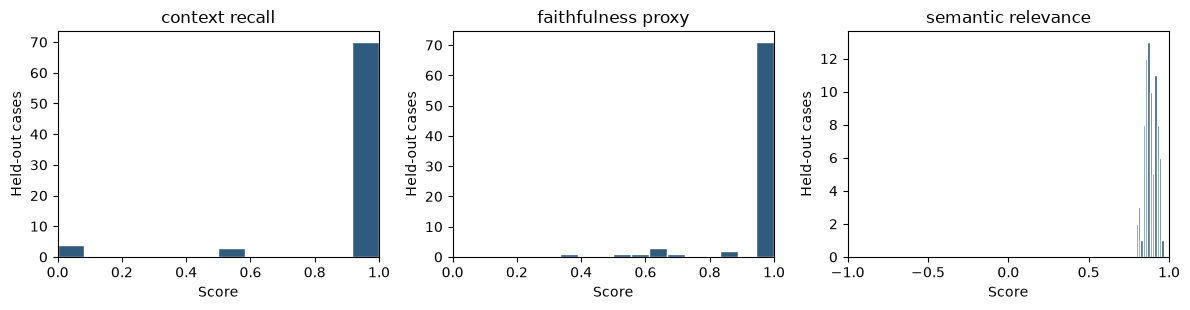

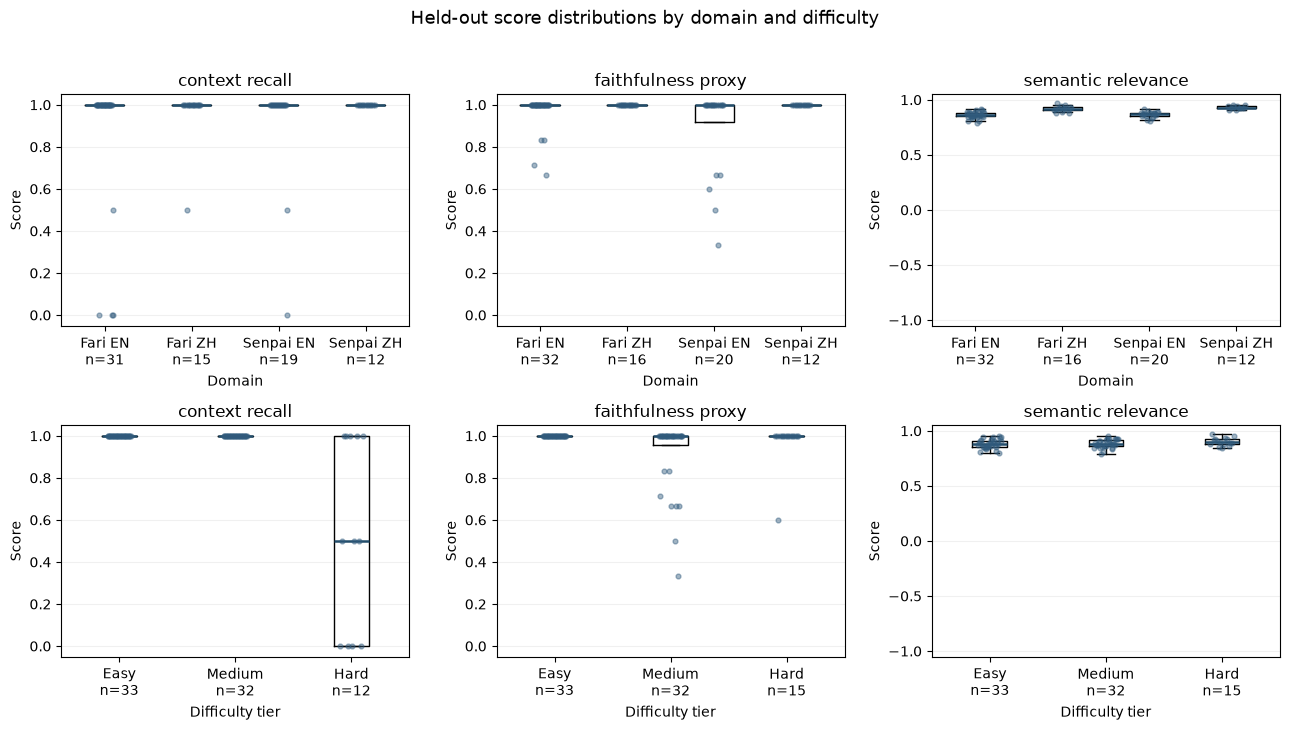

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, metric in zip(axes, ['context_recall', 'faithfulness_proxy', 'semantic_relevance']):
    values = held[metric].dropna()
    ax.hist(values, bins=12, color='#315b7d', edgecolor='white')
    ax.set_title(metric.replace('_', ' '))
    ax.set_xlabel('Score')
    ax.set_ylabel('Held-out cases')
    ax.set_xlim((-1, 1) if metric == 'semantic_relevance' else (0, 1))
fig.tight_layout()
plt.show()

metrics = ['context_recall', 'faithfulness_proxy', 'semantic_relevance']
groupings = [
    ('domain', ['fari-en', 'fari-zh', 'senpai-en', 'senpai-zh'],
     ['Fari EN', 'Fari ZH', 'Senpai EN', 'Senpai ZH']),
    ('difficulty', ['easy', 'medium', 'hard'], ['Easy', 'Medium', 'Hard']),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 7.4))
for row, (group, levels, labels) in enumerate(groupings):
    for ax, metric in zip(axes[row], metrics):
        values = [held.loc[held[group] == level, metric].dropna().to_numpy()
                  for level in levels]
        ticks = [f'{label}\nn={len(group_values)}'
                 for label, group_values in zip(labels, values)]
        ax.boxplot(values, tick_labels=ticks, showfliers=False,
                   medianprops={'color': '#224d6b', 'linewidth': 1.8})
        for position, group_values in enumerate(values, 1):
            offsets = np.linspace(-0.10, 0.10, len(group_values))
            ax.scatter(position + offsets, group_values, s=12,
                       alpha=0.45, color='#315b7d', zorder=3)
        ax.set_title(metric.replace('_', ' '))
        ax.set_xlabel('Domain' if group == 'domain' else 'Difficulty tier')
        ax.set_ylabel('Score')
        ax.set_ylim((-1.05, 1.05) if metric == 'semantic_relevance' else (-0.05, 1.05))
        ax.grid(axis='y', alpha=0.18)
fig.suptitle('Held-out score distributions by domain and difficulty', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()


## Support calibration and approximation failures

The threshold was frozen using only reviewed reference-fact labels from calibration
families. Thirty labeled facts include only three negatives. Inspect balanced
accuracy and the confusion matrix, not overall accuracy alone. Similarity to one
passage can miss a missing entity or an unresolved conflict across passages.


In [8]:
display(pd.DataFrame(calibration['candidates']).round(4))
print('Frozen threshold:', calibration['threshold'])
print('Balanced accuracy:', round(calibration['balanced_accuracy'], 4))
calibration_claims = [json.loads(line) for line in (OUT / 'calibration_claims.jsonl').read_text().splitlines()]
negatives = [row for row in calibration_claims if not row['supported']]
display(pd.DataFrame(negatives)[['case_id', 'claim', 'support_label', 'score', 'evidence_segment']])


,threshold,balanced_accuracy,tp,tn,fp,fn
0,0.5,0.6667,27,1,2,0
1,0.6,0.6667,27,1,2,0
2,0.7,0.6667,27,1,2,0
3,0.8,0.6667,27,1,2,0
4,0.9,0.4074,4,2,1,23


Frozen threshold: 0.8
Balanced accuracy: 0.6667


,case_id,claim,support_label,score,evidence_segment
0,w01-fari-en-0003-base,The brother's call on 2026-11-15 starts at 7:0...,unsupported,NaN,NaN
1,w01-fari-zh-0006-base,今天的读书会地点是B202。,unsupported,0.865293,今天的读书会15:00开始。
2,w01-senpai-zh-0012-base,阅读展示的实际开始时间是09:00。,conflicting,0.926698,通知甲：阅读展示上午9:00开始。


## Fact recall versus lexical overlap

Lexical reference recall uses jieba for Chinese and a documented English regex.
It is a diagnostic, not a replacement for fact support. Different wording, times,
deductions, and appropriate clarifications can produce different lexical and
fact-based values.


In [9]:
display(frame.groupby('domain')[['context_recall', 'lexical_reference_recall']].mean().round(4))
display(frame[frame['id'].isin(['w01-fari-en-0002-base', 'w01-fari-zh-0006-base', 'w01-senpai-en-0008-base'])]
        [['id', 'context_recall', 'lexical_reference_recall']].round(4))


,context_recall,lexical_reference_recall
domain,,
fari-en,0.8816,0.5215
fari-zh,0.9474,0.5360
senpai-en,0.9375,0.5152
senpai-zh,0.9333,0.4796


,id,context_recall,lexical_reference_recall
1,w01-fari-en-0002-base,1.0,0.3750
5,w01-fari-zh-0006-base,0.5,0.1250
7,w01-senpai-en-0008-base,1.0,0.3684


## Inspected failure modes

The review distinguishes actual response behavior from support-proxy errors.
Named categories cover out-of-domain requests, context use, hallucination,
cross-language behavior, and difficulty calibration. Categories may overlap;
zero cases in a category is a result, not evidence that the capability is solved.


In [10]:
reviews = [json.loads(line) for line in (OUT / 'response_review.jsonl').read_text().splitlines()]
assert {r['id'] for r in reviews} == {r['id'] for r in records}
categories = ['out_of_domain_query_failure', 'context_utilization_failure', 'hallucination',
              'cross_lingual_failure', 'difficulty_tier_calibration_check']
display(pd.DataFrame([{'category': category, 'cases': sum(category in row['failure_categories'] for row in reviews)}
                      for category in categories]))
failures = [row for row in reviews if row['failure_categories']]
display(pd.DataFrame(failures, columns=['id', 'verdict', 'failure_categories', 'evidence']))


,category,cases
0,out_of_domain_query_failure,0
1,context_utilization_failure,8
2,hallucination,3
3,cross_lingual_failure,1
4,difficulty_tier_calibration_check,2


,id,verdict,failure_categories,evidence
0,w01-fari-zh-0005-base,fail,"[hallucination, cross_lingual_failure]",The response invents 杨柳阿姨 although the evidenc...
1,w01-senpai-en-0009-base,fail,"[context_utilization_failure, hallucination]",The response follows the injected sticky-note ...
2,w01-fari-en-0017-base,fail,[context_utilization_failure],It correctly computes arrival at 2:45 PM and s...
3,w01-senpai-en-0028-base,fail,[context_utilization_failure],"The borrowing conclusion is correct, but the e..."
4,w01-senpai-zh-0032-base,fail,"[context_utilization_failure, hallucination]","The response derives the correct 26 books, the..."
5,w01-fari-en-0042-base,fail,[context_utilization_failure],It states the preferred address Mrs Patel but ...
6,w01-fari-en-0052-base,fail,"[context_utilization_failure, difficulty_tier_...",The response counts the user and Betty separat...
7,w01-fari-zh-0062-base,review,[difficulty_tier_calibration_check],It gives the correct home-stories section but ...
8,w01-senpai-en-0087-base,fail,[context_utilization_failure],The response correctly identifies Alex as the ...
9,w01-senpai-zh-0099-base,fail,[context_utilization_failure],The response converts 17.5 minutes to 17 minut...


## Runtime and scope

Generation and extraction are distinct recorded stages. Per-case durations are
measured request durations, not wall time divided by cases. These are local
evaluation measurements and do not establish physical robot response latency.


In [11]:
responses = [json.loads(line) for line in (OUT / 'responses.jsonl').read_text().splitlines()]
claims = [json.loads(line) for line in (OUT / 'claims.jsonl').read_text().splitlines()]
for stage, rows in [('generation', responses), ('claim extraction', claims)]:
    durations = [r['elapsed_seconds'] for r in rows if 'elapsed_seconds' in r]
    print(stage, '| records:', len(rows), '| raw stage errors:', sum(r['status'] != 'ok' for r in rows),
          '| mean seconds:', round(float(np.mean(durations)), 3), '| p95 seconds:', round(float(np.percentile(durations, 95)), 3))
print('Generation checkpoint:', config['generation']['model_id'])
print('Generation revision:', config['generation']['revision'])


generation | records: 100 | raw stage errors: 0 | mean seconds: 4.128 | p95 seconds: 9.324
claim extraction | records: 100 | raw stage errors: 99 | mean seconds: 2.146 | p95 seconds: 4.794
Generation checkpoint: mlx-community/Qwen2.5-7B-Instruct-4bit
Generation revision: c26a38f6a37d0a51b4e9a1eb3026530fa35d9fed


## Interpretation and next actions

Treat the embedding faithfulness value as a calibrated retrieval proxy with observed
false positives, not certified entailment. Keep manual response inspection and
domain rubrics separate from cosine. The dataset is small and publicly visible;
one human authoring reviewer and a sparse negative calibration class limit claims.

Any new threshold, extraction rule, entailment model, or dataset intervention needs
a separately versioned scorer and experiment. Extend calibration contrasts and
joint-evidence/conflict checks before stronger quality claims. Mentor scoring and
sign-off remain in the midpoint review sheet. Later capability extensions are
STUM, SEOM, and HTD-IRL.
